# Data Cleaning and Variable Generation

In [2]:
import pandas as pd
import numpy as np
import os
import csv
import sklearn

In [2]:
# Allowed INFLOW_CD values
allowed_codes = [
    11110, 11140, 11170, 11200, 11215, 11230,
    11260, 11290, 11305, 11320, 11350, 11380,
    11410, 11440, 11470, 11500, 11530, 11545,
    11560, 11590, 11620, 11650, 11680, 11710,
    11740
]

# ✅ Input folder containing all monthly files
input_dir = r"D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터"

# ✅ Output folder
output_dir = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo"

# ✅ Create output folder if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# ✅ Output file name
output_file = os.path.join(output_dir, "ALL_Filtered_Output_2019.csv")

# List to store filtered DataFrames
all_filtered_data = []

# ✅ Loop through months 201901 → 201912
for month in range(1, 13):

    ym = f"2019{month:02d}"   # makes 201901, 201902, ... 201912
    filename = f"Seoul_Park_{ym}.csv"
    file_path = os.path.join(input_dir, filename)

    print("Processing:", file_path)

    # ✅ Read file
    df = pd.read_csv(file_path, sep="|")

    # ✅ Ensure INFLOW_CD is integer
    df["INFLOW_CD"] = df["INFLOW_CD"].astype(int)

    # ✅ Filter rows
    filtered_df = df[df["INFLOW_CD"].isin(allowed_codes)]

    # Append filtered result
    all_filtered_data.append(filtered_df)

# ✅ Combine all months into one DataFrame
final_df = pd.concat(all_filtered_data, ignore_index=True)

# ✅ Save final combined file
final_df.to_csv(output_file, index=False, sep="|")

print("\n✅ Done!")
print("Combined file saved at:")
print(output_file)
print("Total rows:", len(final_df))

Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201901.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201902.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201903.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201904.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201905.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201906.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201907.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201908.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201909.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201910.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201911.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201

In [3]:
# File paths
origin_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\origin_latlong.csv"
park_file   = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_latlong.csv"

# ✅ Load with Korean encoding
origin_df = pd.read_csv(origin_file, encoding="CP949")
park_df   = pd.read_csv(park_file, encoding="utf-8")

# ✅ Merge 1: on INFLOW_CD
merged_df = final_df.merge(
    origin_df,
    on="INFLOW_CD",
    how="left",
    suffixes=("", "_origin")
)

# ✅ Merge 2: on ID
merged_df = merged_df.merge(
    park_df,
    on="ID",
    how="left",
    suffixes=("", "_park")
)

# ✅ Remove duplicate columns (optional)
merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]

merged_df = merged_df.drop(
    columns=[col for col in merged_df.columns if col.endswith("_origin") or col.endswith("_park")]
)

print(merged_df.head(30))

    ID  STD_YM   STD_YMD PARK_NAME  INFLOW_CD   M_0009  M_1014  M_1519  \
0    1  201901  20190101       중랑천      11110     2.47    0.94    9.24   
1    1  201901  20190101       중랑천      11140     2.12    3.36    9.51   
2    1  201901  20190101       중랑천      11170     1.19    1.92   10.10   
3    1  201901  20190101       중랑천      11200   247.12  166.54  361.27   
4    1  201901  20190101       중랑천      11215   112.70   39.41   97.57   
5    1  201901  20190101       중랑천      11230   492.99  238.40  379.36   
6    1  201901  20190101       중랑천      11260   330.61  158.60  405.47   
7    1  201901  20190101       중랑천      11290   224.45  104.94  229.25   
8    1  201901  20190101       중랑천      11305    18.22    6.34   58.83   
9    1  201901  20190101       중랑천      11320   392.38  212.85  574.57   
10   1  201901  20190101       중랑천      11350  1149.20  599.09  964.73   
11   1  201901  20190101       중랑천      11380     0.75    1.48   15.00   
12   1  201901  20190101       중랑천    

In [4]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_JOINED_OUTPUT_utf8.csv"

merged_df.to_csv(output_path, index=False, encoding="utf-8")


In [5]:
# Annual Sum

merged_df_summed = (
    merged_df
    .drop(columns=["STD_YM", "STD_YMD", "????"])   # remove STD_YMD first
    .groupby(["ID", "PARK_NAME", "INFLOW_CD", "DO_GU", "lat", "long", "Latitude", "Longitude"], as_index=False)
    .sum()
)

In [153]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_JOINED_OUTPUT_SUM_utf8.csv"

merged_df_summed.to_csv(output_path, index=False, encoding="utf-8")

In [6]:
import osmnx as ox
import networkx as nx

In [ ]:
df_pairs = merged_df_summed

# df_pairs: your 6925 OD rows
all_points = pd.concat([
    df_pairs[['lat','long']].rename(columns={'lat':'lat1','long':'long1'}),
    df_pairs[['Latitude','Longitude']].rename(columns={'Latitude':'lat1','Longitude':'long1'})
], ignore_index=True)

north, south = all_points['lat1'].max(), all_points['lat1'].min()
east, west   = all_points['long1'].max(), all_points['long1'].min()

# Expand a bit (meters)
G_walk  = ox.graph_from_bbox(north, south, east, west, network_type="walk",  simplify=True)
G_drive = ox.graph_from_bbox(north, south, east, west, network_type="drive", simplify=True)

# Project to a metric CRS for faster nearest-node and reliable geometry ops
G_walk  = ox.project_graph(G_walk)
G_drive = ox.project_graph(G_drive)
#G_drive = ox.graph_from_place(["Seoul, South Korea", "Gyeonggi-do, South Korea"], network_type="drive")

In [ ]:
# Unique origin points (dong centroids)
orig = (df_pairs[['INFLOW_CD','lat','long']]
        .drop_duplicates('INFLOW_CD')
        .reset_index(drop=True))

# Unique park points
park = (df_pairs[['ID','Latitude','Longitude']]
        .drop_duplicates('ID')
        .reset_index(drop=True))

def snap_nodes(G, lat_col, lon_col, df):
    # OSMnx expects X=lon, Y=lat in *unprojected*; but with projected graphs, nearest_nodes expects x/y in graph CRS.
    # So we convert points to GeoSeries in the graph CRS, then pass x/y.
    gdf = ox.geocode_to_gdf("Seoul, South Korea")  # not used; just to access ox utils? (skip)


In [ ]:
import geopandas as gpd
from shapely.geometry import Point

def snap_nodes_projected(G, df, lat_col, lon_col):
    # graph CRS
    crs_graph = G.graph['crs']
    gdf = gpd.GeoDataFrame(
        df.copy(),
        geometry=[Point(xy) for xy in zip(df[lon_col], df[lat_col])],
        crs="EPSG:4326"
    ).to_crs(crs_graph)
    x = gdf.geometry.x.to_numpy()
    y = gdf.geometry.y.to_numpy()
    nodes = ox.distance.nearest_nodes(G, X=x, Y=y)
    return pd.Series(nodes, index=df.index)

orig['node_walk']  = snap_nodes_projected(G_walk,  orig, 'lat', 'long')
orig['node_drive'] = snap_nodes_projected(G_drive, orig, 'lat', 'long')

park['node_walk']  = snap_nodes_projected(G_walk,  park, 'Latitude','Longitude')
park['node_drive'] = snap_nodes_projected(G_drive, park, 'Latitude','Longitude')

In [ ]:
df = df_pairs.merge(orig[['INFLOW_CD','node_walk','node_drive']], on='INFLOW_CD', how='left')
df = df.merge(park[['ID','node_walk','node_drive']].rename(columns={
    'node_walk':'park_node_walk',
    'node_drive':'park_node_drive'
}), on='ID', how='left')

In [ ]:
def shortest_lengths_by_origin(G, df, origin_col, dest_col, weight="length", cutoff=None):
    """
    Returns a numpy array of shortest path lengths for each row in df.
    Groups by origin; runs single-source Dijkstra once per unique origin.
    """
    out = np.full(len(df), np.nan, dtype=float)

    # map row indices by origin
    for o, sub_idx in df.groupby(origin_col).groups.items():
        dest_nodes = df.loc[sub_idx, dest_col].to_numpy()
        dest_set = set(dest_nodes)

        try:
            # Single-source Dijkstra
            lengths = nx.single_source_dijkstra_path_length(G, o, weight=weight, cutoff=cutoff)
        except Exception:
            continue

        # Fill outputs
        out[sub_idx] = [lengths.get(d, np.nan) for d in dest_nodes]

    return out

# Optional cutoff in meters to speed up; set None if unsure.
# For Seoul, a cutoff like 50000 (50 km) is usually safe.
CUTOFF = 700000

df['dist_walk_m']  = shortest_lengths_by_origin(G_walk,  df, 'node_walk',  'park_node_walk',  cutoff=CUTOFF)
df['dist_drive_m'] = shortest_lengths_by_origin(G_drive, df, 'node_drive', 'park_node_drive', cutoff=CUTOFF)

In [ ]:
V_WALK_KMPH  = 4.8
V_DRIVE_KMPH = 22.0  # rough urban average; you can sensitivity-test

df['time_walk_min']  = (df['dist_walk_m']  / 1000) / V_WALK_KMPH  * 60
df['time_drive_min'] = (df['dist_drive_m'] / 1000) / V_DRIVE_KMPH * 60

In [ ]:
def logsum_equiv_cost(cw, cd, lam=0.1, theta_w=0.0, theta_d=0.0):
    """
    Equivalent cost from 2-mode logsum:
      c_eq = -(1/lam) * log( exp(theta_w - lam*cw) + exp(theta_d - lam*cd) )
    cw, cd can be numpy arrays (minutes or meters), same units.
    """
    cw = np.asarray(cw, dtype=float)
    cd = np.asarray(cd, dtype=float)

    # Handle NaNs: if one mode missing, fall back to the other
    c_eq = np.full_like(cw, np.nan)

    both = np.isfinite(cw) & np.isfinite(cd)
    only_w = np.isfinite(cw) & ~np.isfinite(cd)
    only_d = ~np.isfinite(cw) & np.isfinite(cd)

    # stable log-sum-exp
    a = theta_w - lam*cw[both]
    b = theta_d - lam*cd[both]
    m = np.maximum(a, b)
    c_eq[both] = -(1/lam) * (m + np.log(np.exp(a - m) + np.exp(b - m)))

    c_eq[only_w] = cw[only_w]
    c_eq[only_d] = cd[only_d]
    return c_eq

df['c_eq_min'] = logsum_equiv_cost(df['time_walk_min'], df['time_drive_min'], lam=0.1)

In [ ]:
print(df[['dist_walk_m','dist_drive_m','time_walk_min','time_drive_min','c_eq_min']].describe())

# How many missing?
print(df[['dist_walk_m','dist_drive_m']].isna().mean())

In [ ]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dist_logsum.csv"
df = df.drop(columns=["PARK_NAME", "DO_GU", "lat", "long", "Latitude", "Longitude", "orig_in_cc", "park_in_cc", 
"node_walk", "node_drive", "park_node_walk", "park_node_drive"]) 

df.to_csv(output_path, index=False, encoding="utf-8")

In [5]:
# File paths
df_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dist_logsum.csv"

# ✅ Load with Korean encoding
df = pd.read_csv(df_file, encoding="CP949")

In [ ]:
# File paths
parkvar_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_var.csv"
greenarea_file   = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_greenarea_rat.csv"

# ✅ Load with Korean encoding
parkvar_df = pd.read_csv(parkvar_file, encoding="CP949")
greenarea_df   = pd.read_csv(greenarea_file, encoding="utf-8")

# Make ID consistent (string) across all dfs
df["ID"] = df["ID"].astype(str).str.strip()
parkvar_df["ID"] = parkvar_df["ID"].astype(str).str.strip()
greenarea_df["ID"] = greenarea_df["ID"].astype(str).str.strip()


# ✅ Merge 1: park variable
merge_df1 = df.merge(
    parkvar_df,
    on="ID",
    how="left",
    suffixes=("", "_parkvar")
)

# ✅ Merge 2:green area
merged_df1 = merge_df1.merge(
    greenarea_df,
    on="ID",
    how="left",
    suffixes=("", "_greenarea")
)

# ✅ Remove duplicate columns (optional)
merged_df1 = merged_df1.loc[:, ~merged_df1.columns.duplicated()]
merged_df1 = merged_df1.drop(columns=[c for c in merged_df1.columns
                                    if c.endswith("_parkvar") or c.endswith("_greenarea")])


print(merged_df1.head(30))

In [8]:
# File paths
transit_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_bussub.csv"

# ✅ Load with Korean encoding
trnasit_df = pd.read_csv(transit_file, encoding="CP949")

# Make ID consistent (string) across all dfs
merged_df1["ID"] = merged_df1["ID"].astype(str).str.strip()
trnasit_df["ID"] = trnasit_df["ID"].astype(str).str.strip()


# ✅ Merge 1: park variable
merged_df2 = merged_df1.merge(
    trnasit_df,
    on="ID",
    how="left",
    suffixes=("", "_transit")
)

# ✅ Remove duplicate columns (optional)
merged_df2 = merged_df2.loc[:, ~merged_df2.columns.duplicated()]
merged_df2 = merged_df2.drop(columns=[c for c in merged_df2.columns
                                    if c.endswith("_transit")])


print(merged_df2.head(30))

   ID  INFLOW_CD     M_0009     M_1014     M_1519     M_2024     M_2529  \
0   1      11110    2743.79    1295.46    5250.84    9011.49   11209.37   
1   1      11140    3067.71    2442.97    4872.58   12522.09   15656.14   
2   1      11170    3591.36    1905.94    5230.97    9095.59   16085.98   
3   1      11200  133752.70   95632.90  157997.87  216959.75  244180.36   
4   1      11215   64066.00   28410.62   55027.84  101552.79  141508.00   
5   1      11230  275542.79  151796.74  224199.57  224705.83  293643.12   
6   1      11260  185919.87  113038.70  222781.14  299810.93  353003.23   
7   1      11290  113714.39   65442.38  115971.92  180338.02  174443.59   
8   1      11305   16980.26    7924.88   27911.56   51083.51   64884.24   
9   1      11320  193111.94  123831.97  251288.38  247793.64  279380.36   
10  1      11350  614444.67  368386.99  542784.96  630190.36  671469.55   
11  1      11380    3593.02    1723.07    6517.19   16763.96   16476.03   
12  1      11410    2743.

In [9]:
print("Before:", len(merged_df2))
merged_df3 = merged_df2.dropna()
print("After:", len(merged_df3))

Before: 10600
After: 6850


In [10]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
merged_df3.to_csv(output_path, index=False, encoding="utf-8")

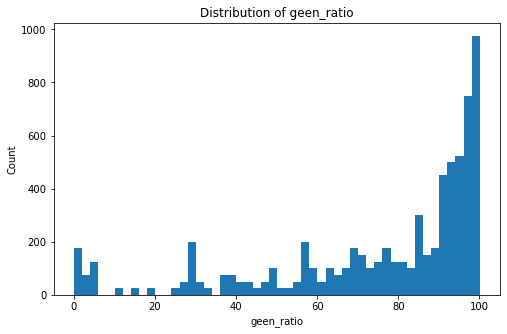

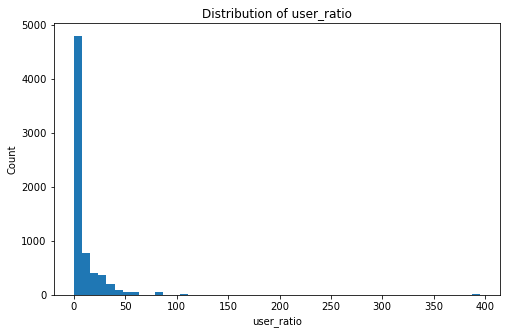

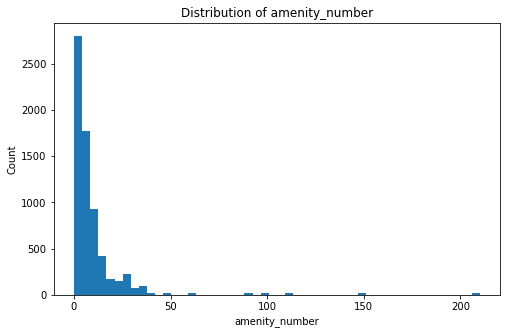

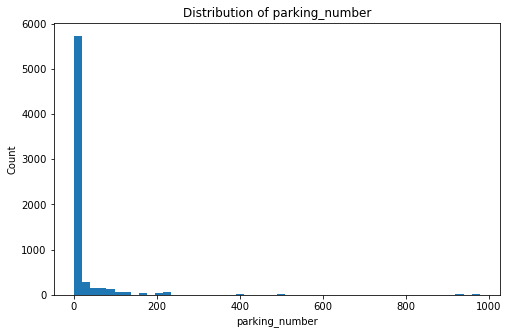

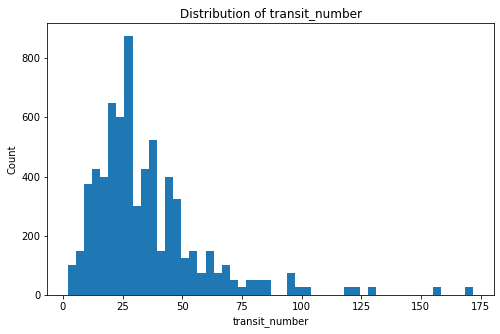

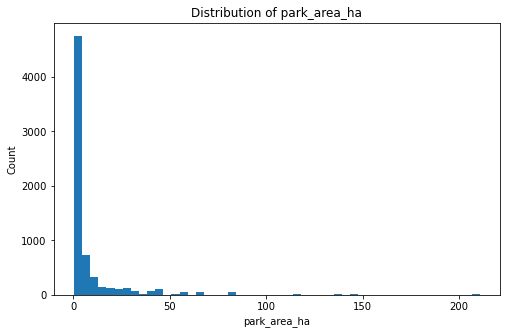

In [32]:
import matplotlib.pyplot as plt

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
merged_df3 = pd.read_csv(output_path, encoding="utf-8")

["parkinglot_number", "parkingcapacity_number", "parkinglot_area", "opensapce_number", 
                "openspaace_area", "road_number", "road_area", "walkingtrail_number", "walkingtrail_area", 
                "plantbed_number", "plantbed_area", "pond_number", "pond_area", "campingsite_number", 
                "campingsite_area", "shadecanopy_number", "shadecanopy_area", "playground_number", 
                "gymtrack_number", "gymtrack_area", "swimmingpool_number", "swimmingpool_area", 
                "sportsfacility_number", "communitycenter_number", "communitycenter_area", "musichall_number", 
                "cafeteria_number", "cafeteria_area", "kiosk_number", "kiosk_area", "greenarea_area", 
                "park_area", "bus500", "bus100", "sub500", "sub100"]


area_vars = ["park_area"]
merged_df3[[a + "_ha" for a in area_vars]] = merged_df3[area_vars] / 10_000

merged_df3["geen_ratio"] = merged_df3["greenarea_area"] / merged_df3["park_area"] *100

merged_df3["user_area"] = (
      merged_df3["openspaace_area"]
    + merged_df3["road_area"]
    + merged_df3["walkingtrail_area"]
    + merged_df3["shadecanopy_area"]
)
merged_df3["user_ratio"] = merged_df3["user_area"] / merged_df3["park_area"] * 100

merged_df3["amenity_number"] = (
      merged_df3["gymtrack_number"]
    + merged_df3["swimmingpool_number"]
    + merged_df3["sportsfacility_number"]
    + merged_df3["playground_number"]
    + merged_df3["cafeteria_number"]
    + merged_df3["kiosk_number"]
)

merged_df3["parking_number"] = merged_df3["parkingcapacity_number"]

merged_df3["transit_number"] = merged_df3["bus500"] + merged_df3["sub500"]

vars_to_plot = ["geen_ratio", "user_ratio", "amenity_number", "parking_number","transit_number", "park_area_ha"]

for var in vars_to_plot:
    x = merged_df3[var].dropna()

    plt.figure(figsize=(8,5))
    plt.hist(x, bins=50)

    plt.title(f"Distribution of {var}")
    plt.xlabel(var)
    plt.ylabel("Count")

    plt.show()

# Compute Accessibility

In [3]:
import re
from scipy.special import logsumexp

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
dt = pd.read_csv(output_path, encoding="utf-8")

# demographic columns like M_0009, W_1014, ...
group_cols = [c for c in dt.columns if re.match(r'^[MW]_\d{4}$', c)]

# basic sanity
assert "INFLOW_CD" in dt.columns
assert "ID" in dt.columns
assert "c_eq_min" in dt.columns

In [6]:
beta = 0.10  # try 0.05, 0.10, 0.20 as sensitivity

# term inside logsumexp: -beta * cost
df["u"] = -beta * df["c_eq_min"]

A_origin = (
    df.groupby("INFLOW_CD")["u"]
      .apply(lambda x: logsumexp(x.values))
      .reset_index(name="A_logsum")
)

print(A_origin.head())

   INFLOW_CD  A_logsum
0      11110  3.291949
1      11140  3.770290
2      11170  3.605955
3      11200  3.636711
4      11215  3.411106


In [8]:
# Example supply weight: park_area (must be >0)
# If park_area repeats by origin (it will), that's fine.

#eps = 1e-6
#df["logS"] = np.log(df["park_area"].clip(lower=eps))
#df["u_supply"] = df["logS"] - beta * df["c_eq_min"]

A_origin_supply = (
    df.groupby("INFLOW_CD")["u_supply"]
      .apply(lambda x: logsumexp(x.values))
      .reset_index(name="A_logsum_supply")
)

KeyError: 'Column not found: u_supply'

In [19]:
# total visitors by origin for each group
origin_group_totals = df.groupby("INFLOW_CD")[group_cols].sum().reset_index()

# merge origin accessibility
origin_stats = origin_group_totals.merge(A_origin, on="INFLOW_CD", how="left")

rows = []
for g in group_cols:
    w = origin_stats[g].to_numpy()
    A = origin_stats["A_logsum"].to_numpy()
    rows.append((g, np.average(A, weights=w)))

group_access = pd.DataFrame(rows, columns=["group", "A_logsum_weighted"])
group_access = group_access.sort_values("A_logsum_weighted", ascending=False)

print(group_access.head(10))

     group  A_logsum_weighted
19  W_3034           3.422007
20  W_3539           3.421197
21  W_4044           3.420211
15  W_1014           3.419474
1   M_1014           3.419351
22  W_4549           3.419187
18  W_2529           3.416170
14  W_0009           3.415947
16  W_1519           3.415559
4   M_2529           3.414450


In [20]:
rows = []
c = df["c_eq_min"].to_numpy()

for g in group_cols:
    w = df[g].to_numpy()
    mask = np.isfinite(c) & (w > 0)
    rows.append((g, np.average(c[mask], weights=w[mask])))

group_realized_cost = pd.DataFrame(rows, columns=["group", "mean_c_eq_min_realized"])
group_realized_cost = group_realized_cost.sort_values("mean_c_eq_min_realized")

print(group_realized_cost.head(10))   # groups traveling least (on average)
print(group_realized_cost.tail(10))   # groups traveling most (on average)

     group  mean_c_eq_min_realized
0   M_0009               27.988728
14  W_0009               28.249624
27  W_7000               28.370745
1   M_1014               28.523893
26  W_6569               28.529406
15  W_1014               28.692702
25  W_6064               28.894833
13  M_7000               28.918493
2   M_1519               29.040232
24  W_5559               29.310722
     group  mean_c_eq_min_realized
3   M_2024               30.700529
10  M_5559               30.761768
9   M_5054               31.211781
17  W_2024               31.344363
4   M_2529               31.359466
6   M_3539               31.377937
18  W_2529               31.392010
8   M_4549               31.407691
7   M_4044               31.439676
5   M_3034               31.601980


In [21]:
def compute_A_origin(df, beta):
    u = -beta * df["c_eq_min"].to_numpy()
    tmp = df[["INFLOW_CD"]].copy()
    tmp["u"] = u
    return tmp.groupby("INFLOW_CD")["u"].apply(lambda x: logsumexp(x.values)).rename(f"A_beta_{beta}")

betas = [0.05, 0.10, 0.20]
A_multi = pd.concat([compute_A_origin(df, b) for b in betas], axis=1).reset_index()
print(A_multi.head())

   INFLOW_CD  A_beta_0.05  A_beta_0.1  A_beta_0.2
0      11110     4.445055    3.291949    1.767210
1      11140     4.684663    3.770290    2.832079
2      11170     4.649444    3.605955    2.178914
3      11200     4.642668    3.636711    2.534145
4      11215     4.514804    3.411106    1.938319


# Plotting Simple Accessibility

In [24]:
def parse_group(g):
    sex = g[0]
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return sex, age_mid

group_access[["sex","age_mid"]] = group_access["group"].apply(
    lambda g: pd.Series(parse_group(g))
)

group_access = group_access.sort_values(["sex","age_mid"])

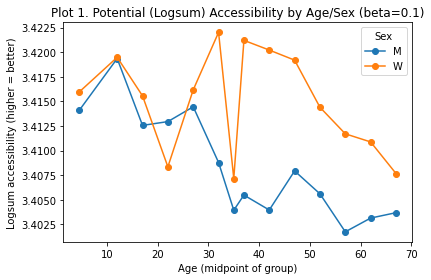

In [27]:
import matplotlib.pyplot as plt
from scipy.special import logsumexp

# Find demographic columns (M_0009, W_1014, ...)
group_cols = [c for c in df.columns if re.match(r'^[MW]_\d{4}$', c)]
assert len(group_cols) > 0, "No demographic columns found like M_0009 / W_1014 etc."

# -----------------------------
# Helper: parse group label
# -----------------------------
def parse_group(g: str):
    """
    g like 'M_0009' or 'W_6064'
    returns (sex, age_lo, age_hi, age_mid)
    """
    sex = g[0]
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return sex, age_lo, age_hi, age_mid

# -----------------------------
# Plot 1: Potential Logsum Accessibility by age/sex
# (composition-weighted by observed visitors across origins)
# -----------------------------
beta = 0.10  # sensitivity try: 0.05, 0.10, 0.20

# Accessibility by origin (dong)
df["u"] = -beta * df["c_eq_min"].astype(float)

A_origin = (
    df.groupby("INFLOW_CD")["u"]
      .apply(lambda x: logsumexp(x.values))
      .reset_index(name="A_logsum")
)

# Total visitors per origin for each group
origin_group_totals = df.groupby("INFLOW_CD")[group_cols].sum().reset_index()

# Merge
origin_stats = origin_group_totals.merge(A_origin, on="INFLOW_CD", how="left")

# Group-weighted accessibility: average A_logsum weighted by group visitors from each origin
rows = []
for g in group_cols:
    weights = origin_stats[g].to_numpy()
    A = origin_stats["A_logsum"].to_numpy()
    if weights.sum() == 0:
        continue
    rows.append((g, np.average(A, weights=weights)))

group_access = pd.DataFrame(rows, columns=["group", "A_logsum_weighted"])

# Add parsing columns and sort
group_access[["sex", "age_lo", "age_hi", "age_mid"]] = group_access["group"].apply(
    lambda x: pd.Series(parse_group(x))
)
group_access = group_access.sort_values(["sex", "age_mid"])

# Plot 1 (lines by sex)
plt.figure()
for sex, sub in group_access.groupby("sex"):
    plt.plot(sub["age_mid"], sub["A_logsum_weighted"], marker="o", label=sex)

plt.xlabel("Age (midpoint of group)")
plt.ylabel("Logsum accessibility (higher = better)")
plt.title(f"Plot 1. Potential (Logsum) Accessibility by Age/Sex (beta={beta})")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()

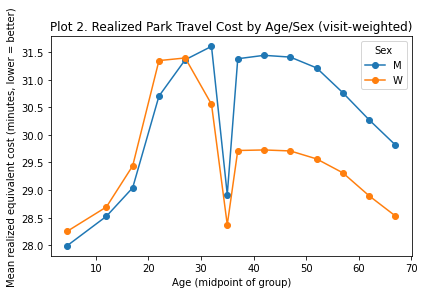

In [28]:
# -----------------------------
# Plot 2: Realized travel cost by age/sex
# (visit-weighted mean c_eq_min using OD flows)
# -----------------------------
rows = []
c = df["c_eq_min"].astype(float).to_numpy()

for g in group_cols:
    w = df[g].to_numpy()
    mask = np.isfinite(c) & (w > 0)
    if mask.sum() == 0:
        continue
    rows.append((g, np.average(c[mask], weights=w[mask])))

group_realized = pd.DataFrame(rows, columns=["group", "mean_c_eq_min_realized"])

# Add parsing columns and sort
group_realized[["sex", "age_lo", "age_hi", "age_mid"]] = group_realized["group"].apply(
    lambda x: pd.Series(parse_group(x))
)
group_realized = group_realized.sort_values(["sex", "age_mid"])

# Plot 2 (lines by sex)
plt.figure()
for sex, sub in group_realized.groupby("sex"):
    plt.plot(sub["age_mid"], sub["mean_c_eq_min_realized"], marker="o", label=sex)

plt.xlabel("Age (midpoint of group)")
plt.ylabel("Mean realized equivalent cost (minutes, lower = better)")
plt.title("Plot 2. Realized Park Travel Cost by Age/Sex (visit-weighted)")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()

In [29]:
def prepare_diff(df, value_col):
    """
    df must contain:
      group, sex, age_mid, value_col
    returns dataframe with Women - Men difference by age
    """
    wide = (
        df.pivot(index="age_mid", columns="sex", values=value_col)
          .dropna(subset=["M", "W"])
          .reset_index()
    )
    wide["W_minus_M"] = wide["W"] - wide["M"]
    return wide

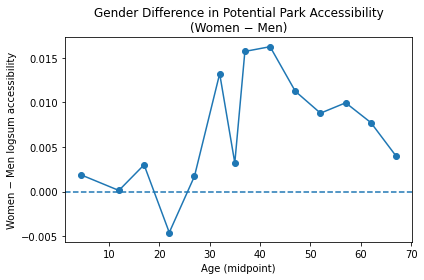

In [30]:
# Prepare difference
diff_access = prepare_diff(
    group_access,
    value_col="A_logsum_weighted"
)

# Plot
plt.figure()
plt.plot(
    diff_access["age_mid"],
    diff_access["W_minus_M"],
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Age (midpoint)")
plt.ylabel("Women − Men logsum accessibility")
plt.title("Gender Difference in Potential Park Accessibility\n(Women − Men)")
plt.tight_layout()
plt.show()

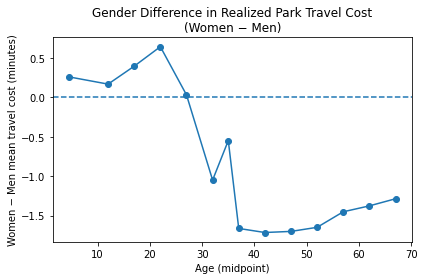

In [31]:
# Prepare difference
diff_realized = prepare_diff(
    group_realized,
    value_col="mean_c_eq_min_realized"
)

# Plot
plt.figure()
plt.plot(
    diff_realized["age_mid"],
    diff_realized["W_minus_M"],
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Age (midpoint)")
plt.ylabel("Women − Men mean travel cost (minutes)")
plt.title("Gender Difference in Realized Park Travel Cost\n(Women − Men)")
plt.tight_layout()
plt.show()

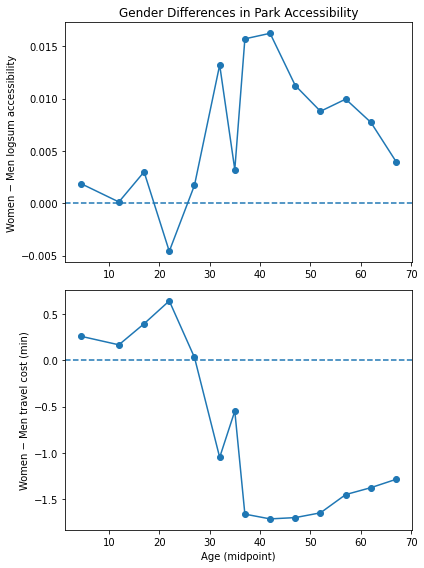

In [32]:
plt.figure(figsize=(6, 8))

plt.subplot(2, 1, 1)
plt.plot(diff_access["age_mid"], diff_access["W_minus_M"], marker="o")
plt.axhline(0, linestyle="--")
plt.ylabel("Women − Men logsum accessibility")
plt.title("Gender Differences in Park Accessibility")

plt.subplot(2, 1, 2)
plt.plot(diff_realized["age_mid"], diff_realized["W_minus_M"], marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Age (midpoint)")
plt.ylabel("Women − Men travel cost (min)")

plt.tight_layout()
plt.show()

# Plotting Selective Accessibility

In [35]:
amenities = [
    "park_area", "openspaace_area", "walkingtrail_area",
    "playground_number", "gymtrack_number", "swimmingpool_number", "sportsfacility_number", 
    "shadecanopy_number", "communitycenter_number", "kiosk_number", 
    "parkingcapacity_number", "bus500", "sub500"
]

In [20]:
import re

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
data = pd.read_csv(output_path, encoding="utf-8")

# demographic columns
group_cols = [c for c in data.columns if re.match(r'^[MW]_\d{4}$', c)]

data_long = data.melt(
    id_vars=["INFLOW_CD", "ID", "c_eq_min"] + amenities,
    value_vars=group_cols,
    var_name="group",
    value_name="visitors"
)

# drop zero-visit rows
data_long = data_long[data_long["visitors"] > 0].copy()


# parse sex & age
def parse_group(g):
    sex = g[0]
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return sex, age_mid

data_long[["sex", "age_mid"]] = data_long["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

In [21]:
area_vars = ["park_area", "openspaace_area", "walkingtrail_area"]
data_long[[a + "_ha" for a in area_vars]] = data_long[area_vars] / 10_000

In [22]:
def parse_group(g):
    sex = 1 if g[0] == "W" else 0   # Female dummy
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return sex, age_mid

data_long[["female", "age_mid"]] = data_long["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

In [36]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Extract amenity matrix
X_amen = data_long[amenities].copy()

# Add constant
X_amen = sm.add_constant(X_amen)

# Compute VIF table
vif_table = pd.DataFrame()
vif_table["Variable"] = X_amen.columns

vif_table["VIF"] = [
    variance_inflation_factor(X_amen.values, i)
    for i in range(X_amen.shape[1])
]

print(vif_table.sort_values("VIF", ascending=False))

                  Variable       VIF
0                    const  5.146206
6      swimmingpool_number  3.325529
10            kiosk_number  2.602357
1                park_area  2.222556
4        playground_number  2.152711
12                  bus500  2.101457
8       shadecanopy_number  1.736265
2          openspaace_area  1.589672
13                  sub500  1.414056
7    sportsfacility_number  1.385360
11  parkingcapacity_number  1.233810
5          gymtrack_number  1.227938
9   communitycenter_number  1.160925
3        walkingtrail_area  1.003854


In [ ]:
import statsmodels.formula.api as smf

formula = (
    "c_eq_min ~ park_area + openspaace_area + walkingtrail_area"
    " + playground_number + gymtrack_number + swimmingpool_number"
    " + sportsfacility_number + shadecanopy_number + communitycenter_number"
    " + kiosk_number + parkingcapacity_number + bus500 + sub500"
)

model = smf.mixedlm(
    formula=formula,
    data=data_long,
    groups=data_long["group"]   # sex-age group random intercept
)

res = model.fit(method="lbfgs")
print(res.summary())

c:\Users\ohdaw\anaconda3\lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\ohdaw\anaconda3\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\ohdaw\anaconda3\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\ohdaw\anaconda3\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\ohdaw\anaconda3\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\ohd

              Mixed Linear Model Regression Results
Model:                MixedLM     Dependent Variable:     c_eq_min
No. Observations:     191750      Method:                 REML    
No. Groups:           28          Scale:                  394.3188
Min. group size:      6834        Log-Likelihood:         inf     
Max. group size:      6850        Converged:              Yes     
Mean group size:      6848.2                                      
------------------------------------------------------------------
                       Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               0.000                                     
park_area               0.000    0.000   8.891 0.000  0.000  0.000
openspaace_area        -0.000    0.000 -14.250 0.000 -0.000 -0.000
walkingtrail_area      -0.002    0.000  -5.716 0.000 -0.002 -0.001
playground_number      -0.035    0.009  -3.895 0.000 -0.053 -0.018
gymtrack_n

In [67]:
import statsmodels.api as sm

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
data = pd.read_csv(output_path, encoding="utf-8")

# demographic columns
group_cols = [c for c in data.columns if re.match(r'^[MW]_\d{4}$', c)]

# -----------------------------
# Rebuild park variables
# -----------------------------
data["geen_ratio"] = data["greenarea_area"] / data["park_area"] *100

data["user_area"] = (
      data["openspaace_area"]
    + data["road_area"]
    + data["walkingtrail_area"]
    + data["shadecanopy_area"]
)
data["user_ratio"] = data["user_area"] / data["park_area"] * 100

data["amenity_number"] = (
      data["gymtrack_number"]
    + data["swimmingpool_number"]
    + data["sportsfacility_number"]
    + data["playground_number"]
    + data["cafeteria_number"]
    + data["kiosk_number"]
)

data["parking_number"] = data["parkingcapacity_number"]

data["transit_number"] = data["bus500"] + data["sub500"]

area_vars = ["park_area"]
data[[a + "_ha" for a in area_vars]] = data[area_vars] / 10_000

# Keep only simplified amenities
amenities = ["geen_ratio", "user_ratio", "amenity_number", "parking_number","transit_number", "park_area_ha"]

# -----------------------------
# Wide → Long demographic format
# -----------------------------
data_long = data.melt(
    id_vars=["INFLOW_CD", "ID", "c_eq_min"] + amenities,
    value_vars=group_cols,
    var_name="group",
    value_name="visitors"
)

# Keep only positive observed visits
data_long = data_long[data_long["visitors"] > 0].copy()

In [69]:
def parse_group(g):
    sex = 1 if g[0] == "W" else 0   # female dummy
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return sex, age_mid

data_long[["female", "age"]] = data_long["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

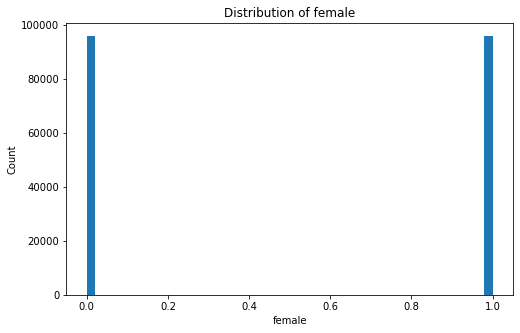

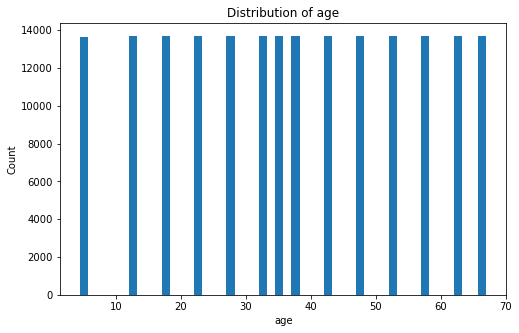

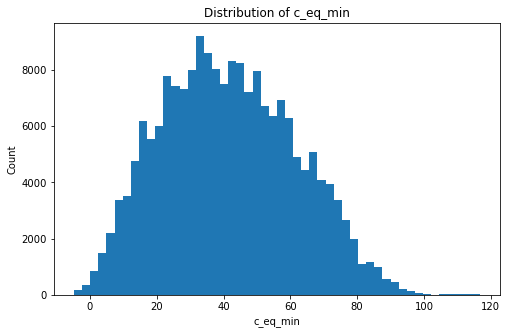

In [43]:
vars_to_plot = ["female", "age", "c_eq_min"]

for var in vars_to_plot:
    x = data_long[var].dropna()

    plt.figure(figsize=(8,5))
    plt.hist(x, bins=50)

    plt.title(f"Distribution of {var}")
    plt.xlabel(var)
    plt.ylabel("Count")

    plt.show()

In [70]:
for a in amenities:
    data_long[f"{a}_F"]  = data_long[a] * data_long["female"]
    #data_long[f"{a}_A"]  = data_long[a] * data_long["age"]
    #data_long[f"{a}_FA"] = data_long[a] * data_long["female"] * data_long["age"]

In [71]:
X_vars = []

# main effects
X_vars += amenities

# sex interactions
X_vars += [f"{a}_F" for a in amenities]

# age interactions
#X_vars += [f"{a}_A" for a in amenities]

# sex-age interactions
#X_vars += [f"{a}_FA" for a in amenities]

X = data_long[X_vars]
X = sm.add_constant(X)

y = data_long["c_eq_min"]
w = data_long["visitors"]

In [72]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Extract amenity matrix
X_amen = data_long[amenities].copy()

# Add constant
X_amen = sm.add_constant(X_amen)

# Compute VIF table
vif_table = pd.DataFrame()
vif_table["Variable"] = X_amen.columns

vif_table["VIF"] = [
    variance_inflation_factor(X_amen.values, i)
    for i in range(X_amen.shape[1])
]

print(vif_table.sort_values("VIF", ascending=False))

         Variable        VIF
0           const  11.148942
5  transit_number   1.807001
6    park_area_ha   1.777547
4  parking_number   1.092061
1      geen_ratio   1.073478
3  amenity_number   1.061697
2      user_ratio   1.058291


In [75]:
model = sm.WLS(y, X, weights=w)
res = model.fit(cov_type="HC1")   # robust SE

print(res.summary())

                            WLS Regression Results                            
Dep. Variable:               c_eq_min   R-squared:                       0.178
Model:                            WLS   Adj. R-squared:                  0.177
Method:                 Least Squares   F-statistic:                     350.3
Date:                Wed, 28 Jan 2026   Prob (F-statistic):               0.00
Time:                        17:46:40   Log-Likelihood:            -1.1042e+06
No. Observations:              191750   AIC:                         2.208e+06
Df Residuals:                  191737   BIC:                         2.209e+06
Df Model:                          12                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               48.4743      0.703  

In [65]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif)

[11.148942935448424, 2.9756669983023976, 5.923295862378687, 6.333333141025353, 6.549880359514495, 9.816768107394154, 10.553145646914695, 3.636762441682911, 2.0610694842011825, 2.396511626101674, 2.2479189380698332, 6.686498268484143, 3.806980345212862, 4.77982020942995, 4.980962971614774, 5.559632457402901, 5.522587398865665, 11.493168402896236, 9.072276073776944]


# Marginal Effect

In [45]:
age_groups = {
    "0-9": 5,
    "10–19": 15,
    "20–29": 25,
    "30–39": 35,
    "40–49": 45,
    "50–59": 55,
    "60–69": 65,
    "70+":   75
}

In [46]:
def marginal_effect(res, var, age, female):
    """
    Marginal effect of park variable var at given age and sex.
    female = 0 (men), 1 (women)
    """
    b   = res.params[var]
    bf  = res.params[f"{var}_F"]
    ba  = res.params[f"{var}_A"]
    bfa = res.params[f"{var}_FA"]

    return b + female*bf + age*ba + female*age*bfa

In [47]:
rows = []

for var in amenities:  # ["park_area","amenity_number","parking_number","transit_number"]
    for label, age in age_groups.items():

        me_m = marginal_effect(res, var, age, female=0)
        me_w = marginal_effect(res, var, age, female=1)

        rows.append({
            "Amenity": var,
            "AgeGroup": label,
            "AgeMid": age,
            "Men_Effect": me_m,
            "Women_Effect": me_w,
            "W_minus_M": me_w - me_m
        })

marginal_table = pd.DataFrame(rows)
print(marginal_table.head())

      Amenity AgeGroup  AgeMid  Men_Effect  Women_Effect  W_minus_M
0  geen_ratio      0-9       5   -0.068942     -0.065743   0.003199
1  geen_ratio    10–19      15   -0.072369     -0.069411   0.002958
2  geen_ratio    20–29      25   -0.075797     -0.073080   0.002716
3  geen_ratio    30–39      35   -0.079224     -0.076749   0.002475
4  geen_ratio    40–49      45   -0.082651     -0.080418   0.002233


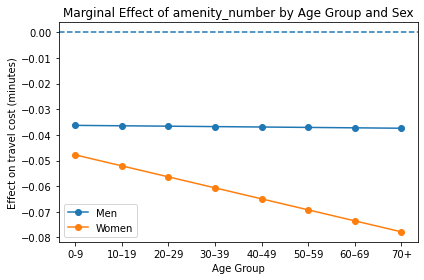

In [48]:
var = "amenity_number"

sub = marginal_table[marginal_table["Amenity"] == var]

plt.figure()
plt.plot(sub["AgeGroup"], sub["Men_Effect"], marker="o", label="Men")
plt.plot(sub["AgeGroup"], sub["Women_Effect"], marker="o", label="Women")

plt.axhline(0, linestyle="--")
plt.title(f"Marginal Effect of {var} by Age Group and Sex")
plt.ylabel("Effect on travel cost (minutes)")
plt.xlabel("Age Group")
plt.legend()
plt.tight_layout()
plt.show()

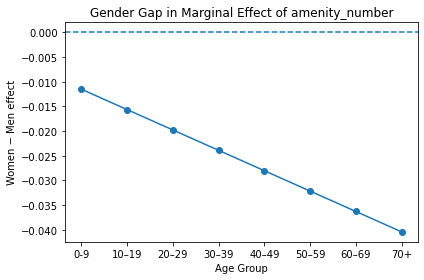

In [49]:
plt.figure()

plt.plot(sub["AgeGroup"], sub["W_minus_M"], marker="o")

plt.axhline(0, linestyle="--")
plt.title(f"Gender Gap in Marginal Effect of {var}")
plt.ylabel("Women − Men effect")
plt.xlabel("Age Group")
plt.tight_layout()
plt.show()

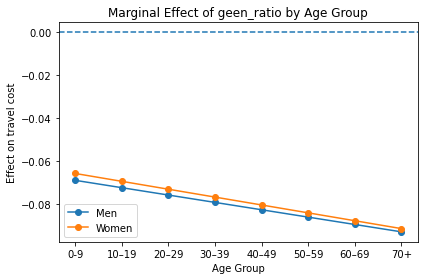

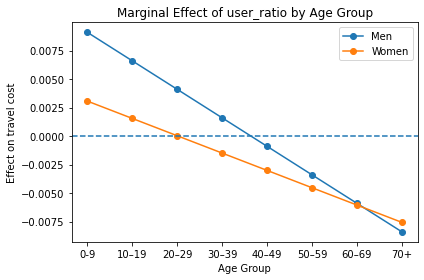

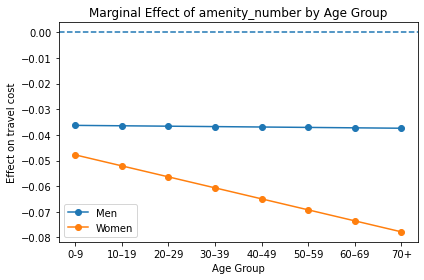

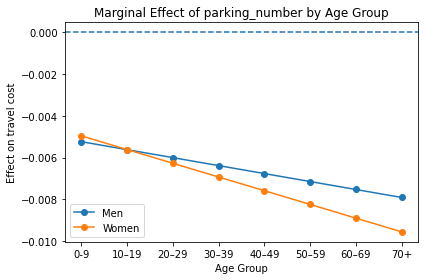

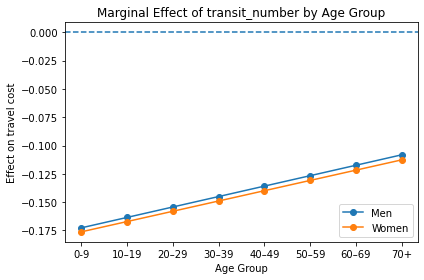

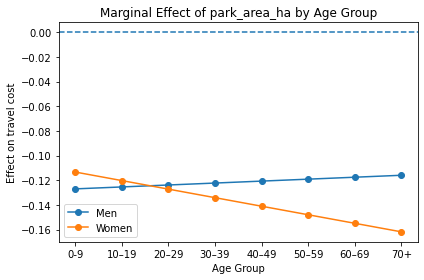

In [50]:
for var in amenities:

    sub = marginal_table[marginal_table["Amenity"] == var]

    plt.figure()
    plt.plot(sub["AgeGroup"], sub["Men_Effect"], marker="o", label="Men")
    plt.plot(sub["AgeGroup"], sub["Women_Effect"], marker="o", label="Women")

    plt.axhline(0, linestyle="--")
    plt.title(f"Marginal Effect of {var} by Age Group")
    plt.ylabel("Effect on travel cost")
    plt.xlabel("Age Group")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [76]:
#marginal_table.to_csv("marginal_effects_by_agegroup.csv", index=False)
#print("Saved: marginal_effects_by_agegroup.csv")

print(marginal_table)

           Amenity AgeGroup  AgeMid  Men_Effect  Women_Effect  W_minus_M
0       geen_ratio      0-9       5   -0.068942     -0.065743   0.003199
1       geen_ratio    10–19      15   -0.072369     -0.069411   0.002958
2       geen_ratio    20–29      25   -0.075797     -0.073080   0.002716
3       geen_ratio    30–39      35   -0.079224     -0.076749   0.002475
4       geen_ratio    40–49      45   -0.082651     -0.080418   0.002233
5       geen_ratio    50–59      55   -0.086079     -0.084086   0.001992
6       geen_ratio    60–69      65   -0.089506     -0.087755   0.001751
7       geen_ratio      70+      75   -0.092933     -0.091424   0.001509
8       user_ratio      0-9       5    0.009107      0.003074  -0.006033
9       user_ratio    10–19      15    0.006607      0.001554  -0.005053
10      user_ratio    20–29      25    0.004107      0.000035  -0.004072
11      user_ratio    30–39      35    0.001607     -0.001485  -0.003092
12      user_ratio    40–49      45   -0.000893    